<a href="https://colab.research.google.com/github/karizma-pinkney/cms-dimuon-analysis/blob/main/CMS_Dimuon_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reconstructing Particle Masses from CMS Open Data

Author: Karizma Pinkney

Independent educational project using public CMS data from CERN. Not an official CMS collaboration project.

Goal: Load a dataset of muon pairs, plot their invariant mass, and calculate those masses myself from energy to momentum.

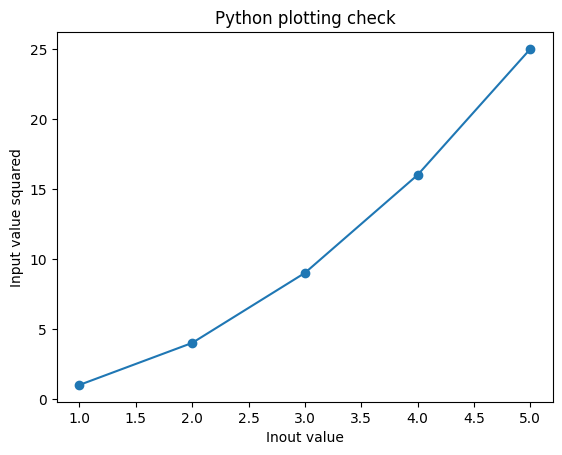

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

values = np.array([1,2,3,4,5])

plt.plot(values, values**2,
         marker="o")
plt.xlabel("Inout value")
plt.ylabel("Input value squared")
plt.title("Python plotting check")
plt.show()

In [7]:
import pandas as pd
import requests

url = "http://opendata.cern.ch/record/545/files/Dimuon_DoubleMu.csv"

response = requests.get(url)
with open("Dimuon_DoubleMu.csv", "wb") as f:
  f.write(response.content)

data = pd.read_csv("Dimuon_DoubleMu.csv")

print("Rows in the files:", len(data))
print()
data.head()

Rows in the files: 100000



,Run,Event,type1,E1,px1,py1,pz1,pt1,eta1,phi1,...,type2,E2,px2,py2,pz2,pt2,eta2,phi2,Q2,M
0,165617,74601703,G,9.6987,-9.5104,0.3662,1.8633,9.5175,0.1945,3.1031,...,G,9.7633,7.3277,-1.1524,6.3473,7.4178,0.7756,-0.1560,1,17.4922
1,165617,75100943,G,6.2039,-4.2666,0.4565,-4.4793,4.2910,-0.9121,3.0350,...,G,9.6690,7.2740,-2.8211,-5.7104,7.8019,-0.6786,-0.3700,1,11.5534
2,165617,75587682,G,19.2892,-4.2121,-0.6516,18.8121,4.2622,2.1905,-2.9881,...,G,9.8244,4.3439,-0.4735,8.7985,4.3697,1.4497,-0.1086,1,9.1636
3,165617,75660978,G,7.0427,-6.3268,-0.2685,3.0802,6.3325,0.4690,-3.0992,...,G,5.5857,4.4748,0.8489,-3.2319,4.5546,-0.6605,0.1875,1,12.4774
4,165617,75947690,G,7.2751,0.1030,-5.5331,-4.7212,5.5340,-0.7736,-1.5522,...,G,7.3181,-0.3988,6.9408,2.2825,6.9523,0.3227,1.6282,1,14.3159


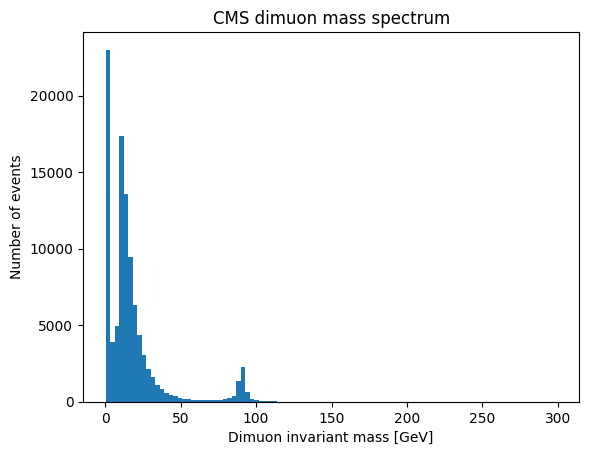

In [8]:
import matplotlib.pyplot as plt

mass = data["M"]

plt.hist(mass, bins=100)
plt.xlabel("Dimuon invariant mass [GeV]")
plt.ylabel("Number of events")
plt.title("CMS dimuon mass spectrum")
plt.show()

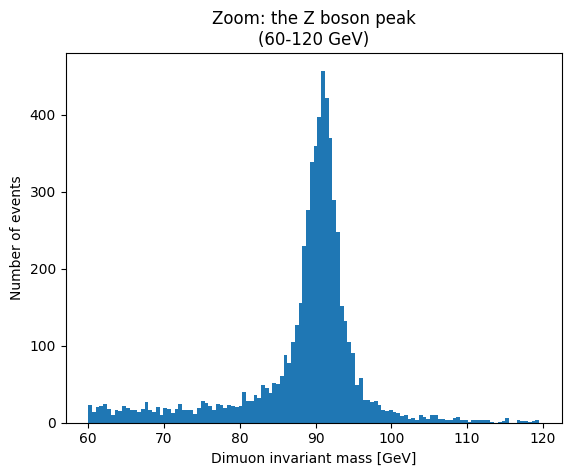

In [9]:
mas = data["M"]

z_region = mas[(mas > 60) & (mas < 120)]

plt.hist(z_region, bins=120)
plt.xlabel("Dimuon invariant mass [GeV]")
plt.ylabel("Number of events")
plt.title("Zoom: the Z boson peak\n(60-120 GeV)")
plt.show()

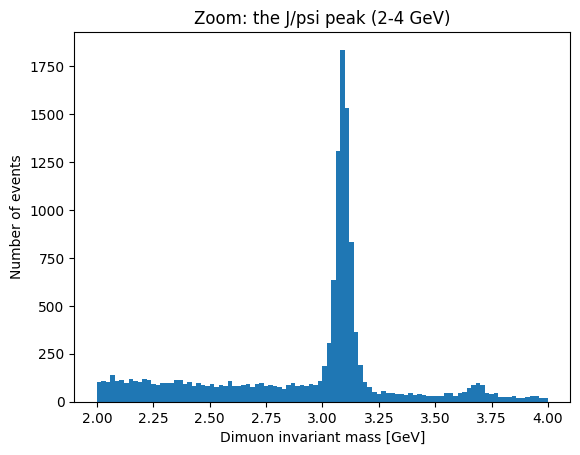

In [10]:
jpsi_region = mass[(mass > 2) & (mass < 4)]

plt.hist(jpsi_region, bins=100)
plt.xlabel("Dimuon invariant mass [GeV]")
plt.ylabel("Number of events")
plt.title("Zoom: the J/psi peak (2-4 GeV)")
plt.show()

In [11]:
import numpy as np

total_energy = data["E1"] + data["E2"]
total_px = data["px1"] + data["px2"]
total_py = data["py1"] + data["py2"]
total_pz = data["pz1"] + data["pz2"]

total_momentum_squared = total_px**2 + total_py**2 + total_pz**2

my_mass = np.sqrt(total_energy**2 - total_momentum_squared)

print("My calculated mass, first 5 values:")
print(my_mass.head())
print()
print("CMS supplied mass, first 5 values:")
print(data["M"].head())

My calculated mass, first 5 values:
0    17.492090
1    11.553492
2     9.163692
3    12.477448
4    14.315904
dtype: float64

CMS supplied mass, first 5 values:
0    17.4922
1    11.5534
2     9.1636
3    12.4774
4    14.3159
Name: M, dtype: float64


/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in sqrt
  result = getattr(ufunc, method)(*inputs, **kwargs)


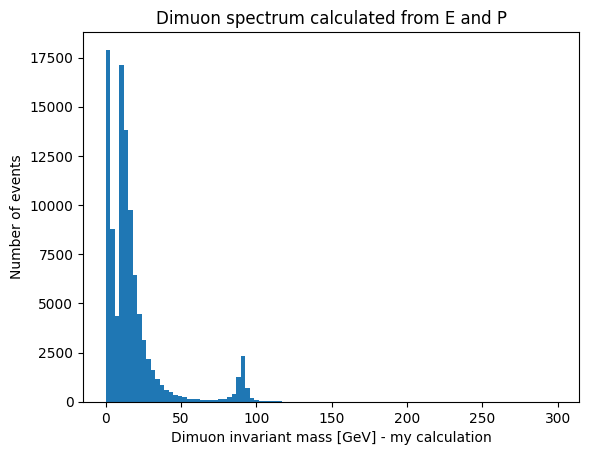

In [12]:
plt.hist(my_mass, bins=100)
plt.xlabel("Dimuon invariant mass [GeV] - my calculation")
plt.ylabel("Number of events")
plt.title("Dimuon spectrum calculated from E and P")
plt.show()

In [13]:
difference = my_mass - data ["M"]

print("Events when my calculation is NaN:", my_mass.isna().sum())
print("Average difference from CMS:", difference.abs().mean(), "GeV")
print("Largest difference from CMS:", difference.abs().max(), "GeV")

Events when my calculation is NaN: 1
Average difference from CMS: 0.0003684252935262137 GeV
Largest difference from CMS: 0.8291972087026647 GeV


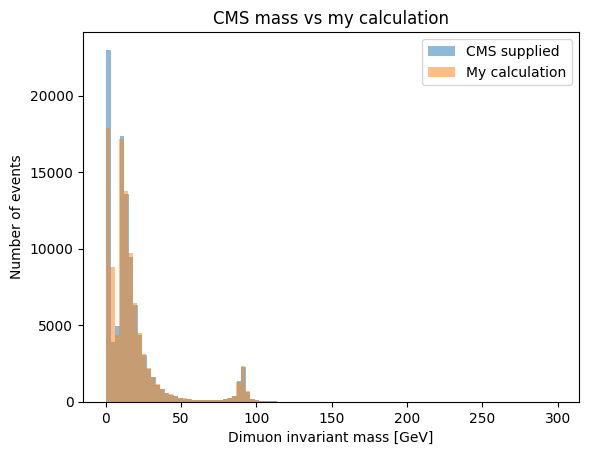

In [14]:
plt.hist(data["M"], bins=100, alpha=0.5, label="CMS supplied")
plt.hist(my_mass, bins=100, alpha=0.5, label="My calculation")
plt.xlabel("Dimuon invariant mass [GeV]")
plt.ylabel("Number of events")
plt.title("CMS mass vs my calculation")
plt.legend()
plt.show()

In [15]:
difference = my_mass - data["M"]

print("Events differing by more than 0.01 GeV:", (difference.abs() > 0.01).sum())
print("CMS masses below 3 GeV:", (data["M"] < 3).sum())
print("My masses below 3 GeV:", (my_mass < 3).sum())

Events differing by more than 0.01 GeV: 197
CMS masses below 3 GeV: 15461
My masses below 3 GeV: 15458


Number of outlier events: 197
Smallest CMS mass among them: 0.3007
Largest CMS mass among them: 25.8176



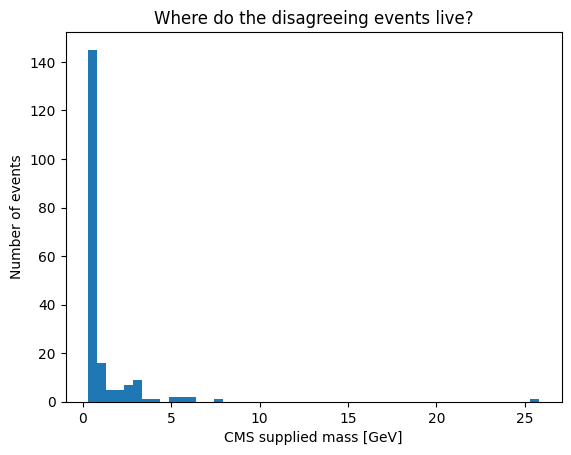

In [16]:
outlier_mask = difference.abs() > 0.01

outlier_masses = data.loc[outlier_mask, "M"]

print("Number of outlier events:", len(outlier_masses))
print("Smallest CMS mass among them:", outlier_masses.min())
print("Largest CMS mass among them:", outlier_masses.max())
print()

plt.hist(outlier_masses, bins=50)
plt.xlabel("CMS supplied mass [GeV]")
plt.ylabel("Number of events")
plt.title("Where do the disagreeing events live?")
plt.show()

Number of outlier events: 197
Smallest CMS mass among them: 0.3007
Largest CMS mass among them: 25.8176



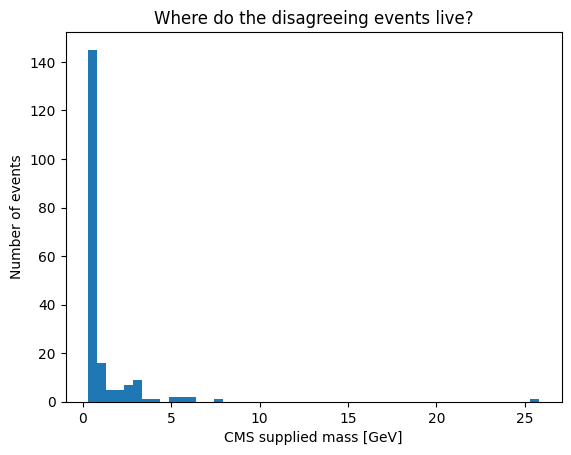

In [17]:
outlier_mask = difference.abs() > 0.01

outlier_masses = data.loc[outlier_mask, "M"]

print("Number of outlier events:", len(outlier_masses))
print("Smallest CMS mass among them:", outlier_masses.min())
print("Largest CMS mass among them:", outlier_masses.max())
print()

plt.hist(outlier_masses, bins=50)
plt.xlabel("CMS supplied mass [GeV]")
plt.ylabel("Number of events")
plt.title("Where do the disagreeing events live?")
plt.show()

In [18]:
bins = [0, 1, 3, 10, 30, 100, 300]
mass_range = pd.cut(data["M"], bins=bins)

summary = pd.DataFrame({
    "events": data.groupby(mass_range, observed=True).size(),
    "outliers": data[outlier_mask].groupby(mass_range[outlier_mask], observed=True).size()
}).fillna(0)

summary["outlier_percent"] = 100 * summary["outliers"] / summary["events"]
print(summary)

            events  outliers  outlier_percent
M                                            
(0, 1]        4626     153.0         3.307393
(1, 3]       10835      26.0         0.239963
(3, 10]      21782      17.0         0.078046
(10, 30]     50739       1.0         0.001971
(30, 100]    11747       0.0         0.000000
(100, 300]     271       0.0         0.000000
